# DR1 cycle 1: MetaCal vs LensMC, South vs North

Puts the four runs (`DR1_{south,north}_{metaCal,lensMC}_power_spectra_and_covariance.ipynb`) on the same axes. It reads
only their `results_summary_*.npz` files, so run those four notebooks first. The figures go to
`report/figures/` for `report/DR1_cycle1_QML_summary.tex`.

All numbers use the kept pixels (noisy pixels removed). "Noise removed" means minus the analytic shape noise
$N = \sigma_\epsilon^2/\bar n_{\rm eff}$ of the run.

⚠︎ The DR1 data are unblinded and restricted to the B-Mode Tiger Team.

In [1]:
import os

import numpy as np
from scipy.stats import chi2 as chi2_dist
from matplotlib import pyplot as plt
import seaborn as sns

sns.set(font_scale=1.25, rc={'text.usetex': False, 'figure.dpi': 300})
sns.set_style('ticks', {'axes.grid': True})

cycle_dir = os.path.abspath(os.getcwd())
fig_dir = f'{cycle_dir}/report/figures'
os.makedirs(fig_dir, exist_ok=True)

METHODS = {'metacal': ('MetaCal', '#2a78d6', 'o'), 'lensmc': ('LensMC', '#eb6834', 's')}
FIELDS = {'north': 'North', 'south': 'South'}
INK = '#52514e'

runs = {(m, f): dict(np.load(f'{cycle_dir}/data/{m}/{f}/results_summary_{f}_N64_lmax150_maps10_neff0.5.npz'))
        for m in METHODS for f in FIELDS}
r0 = runs['metacal', 'south']
ell_bp, edges = r0['ell_bp'], r0['ell_bp_edges']
n_bands = len(ell_bp)
null_bands = slice(0, 5)   # ell 10-109: below the top two bands, which are high in every run (aliasing above 2 N_side)
print('bands', [f'{a}-{b - 1}' for a, b in zip(edges[:-1], edges[1:])])

bands ['10-29', '30-49', '50-69', '70-89', '90-109', '110-129', '130-150']


## Derived quantities

For each run: QML and pseudo-$C_\ell$ errors, $E$ and $B$ with the noise removed, the fiducial $E$ signal averaged over
each band (pixel window included), and the $B$-mode $\chi^2$ with the full QML covariance.

In [2]:
def band_average(cl):
    return np.array([cl[a:b].mean() for a, b in zip(edges[:-1], edges[1:])])


def chi2_pte(d, cov):
    x2 = d @ np.linalg.solve(cov, d)
    return x2, chi2_dist.sf(x2, len(d))


for (m, f), r in runs.items():
    cov = r['cov_QML']
    r['sig_EE'], r['sig_BB'] = np.sqrt(np.diag(cov)[:n_bands]), np.sqrt(np.diag(cov)[n_bands:])
    r['ratio_EE'] = np.sqrt(np.diag(r['cov_EE_EE_PCl'])) / r['sig_EE']
    r['ratio_BB'] = np.sqrt(np.diag(r['cov_BB_BB_PCl'])) / r['sig_BB']
    r['EE_sig'] = r['cl_EE_QML'] - r['cl_noise']
    r['BB_sig'] = r['cl_BB_QML'] - r['cl_noise']
    r['theory_b'] = band_average(r['cl_EE_theory_pw'])
    r['chi2_BB'], r['pte_BB'] = chi2_pte(r['BB_sig'][null_bands], cov[n_bands:, n_bands:][null_bands, null_bands])
    r['chi2_EE'], r['pte_EE'] = chi2_pte((r['EE_sig'] - r['theory_b'])[null_bands], cov[:n_bands, :n_bands][null_bands, null_bands])

np.set_printoptions(linewidth=150)
for (m, f), r in runs.items():
    print(f'--- {FIELDS[f]} {METHODS[m][0]}: {r["n_pix_mask"]}/{r["n_pix_nocut"]} pixels kept, '
          f'n_eff {r["density_arcmin2"]:.1f}/arcmin^2, sigma_e {r["sigma_e"]:.3f}, N {r["cl_noise"]:.3g}')
    print('  sigma PCl/QML  EE', np.round(r['ratio_EE'], 1), '  BB', np.round(r['ratio_BB'], 1))
    print('  (EE - N - theory)/sigma', np.round((r['EE_sig'] - r['theory_b']) / r['sig_EE'], 1))
    print('  (BB - N)/sigma         ', np.round(r['BB_sig'] / r['sig_BB'], 1))
    print('  (BB - N)/EE theory     ', np.round(r['BB_sig'] / r['theory_b'], 2))
    print(f'  ell 10-109: EE chi2 {r["chi2_EE"]:.1f}/5 (PTE {r["pte_EE"]:.2g}),  '
          f'BB null chi2 {r["chi2_BB"]:.1f}/5 (PTE {r["pte_BB"]:.2g})')

--- North MetaCal: 533/711 pixels kept, n_eff 16.3/arcmin^2, sigma_e 0.279, N 4.04e-10
  sigma PCl/QML  EE [4.  2.  1.6 1.4 1.3 1.3 1.5]   BB [17.3  6.5  3.1  1.8  1.3  1.1  1.1]
  (EE - N - theory)/sigma [-0.7 -0.2 -0.5 -1.   0.6  1.5  3.9]
  (BB - N)/sigma          [-0.   0.5  1.7 -1.2  1.6  0.3  8.1]
  (BB - N)/EE theory      [-0.    0.02  0.06 -0.05  0.07  0.02  0.51]
  ell 10-109: EE chi2 2.5/5 (PTE 0.77),  BB null chi2 7.0/5 (PTE 0.22)
--- South MetaCal: 1721/2132 pixels kept, n_eff 18.1/arcmin^2, sigma_e 0.280, N 3.66e-10
  sigma PCl/QML  EE [1.8 1.5 1.3 1.2 1.2 1.2 1.3]   BB [13.2  3.6  2.1  1.4  1.2  1.1  1. ]
  (EE - N - theory)/sigma [-1.3  0.  -1.3  0.8  1.6 -0.   6.1]
  (BB - N)/sigma          [5.6 0.6 4.7 2.1 3.6 4.3 9. ]
  (BB - N)/EE theory      [0.06 0.01 0.05 0.03 0.06 0.09 0.23]
  ell 10-109: EE chi2 6.5/5 (PTE 0.26),  BB null chi2 84.8/5 (PTE 8.1e-17)
--- North LensMC: 534/711 pixels kept, n_eff 17.7/arcmin^2, sigma_e 0.263, N 3.31e-10
  sigma PCl/QML  EE [4.1 2.  1

## Error-bar ratio

Pseudo-$C_\ell$ (NaMaster) errors divided by QML errors; above 1 QML is more precise.

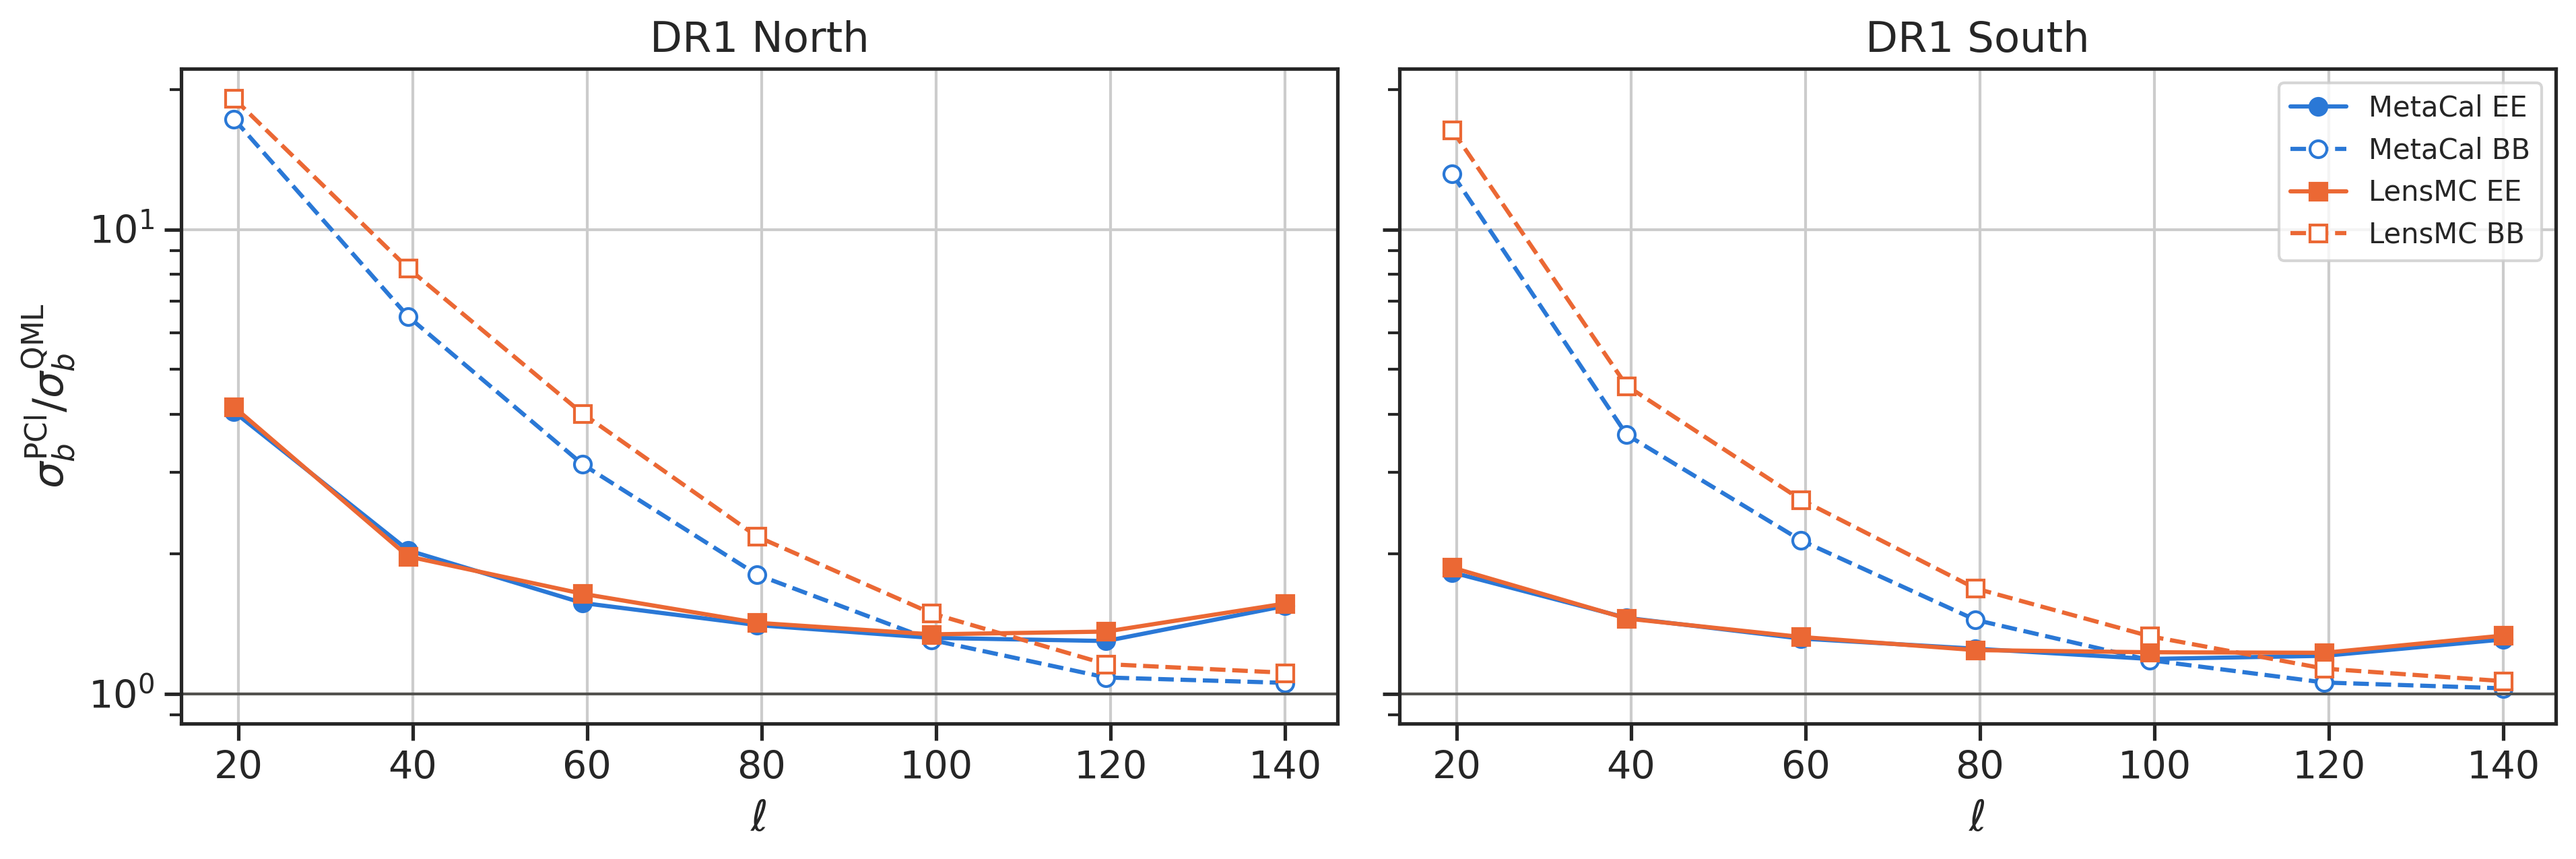

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (f, flabel) in zip(axes, FIELDS.items()):
    for m, (mlabel, col, mk) in METHODS.items():
        r = runs[m, f]
        ax.plot(ell_bp, r['ratio_EE'], '-' + mk, color=col, label=f'{mlabel} EE')
        ax.plot(ell_bp, r['ratio_BB'], '--' + mk, color=col, mfc='white', label=f'{mlabel} BB')
    ax.axhline(1, color=INK, lw=1)
    ax.set_yscale('log')
    ax.set_xlabel('ℓ')
    ax.set_title(f'DR1 {flabel}')
axes[0].set_ylabel('$\\sigma^{\\rm PCl}_b / \\sigma^{\\rm QML}_b$')
axes[1].legend(fontsize=10)
fig.tight_layout()
fig.savefig(f'{fig_dir}/sigma_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

## E-modes

QML $E$-mode bandpowers with the noise removed, against the fiducial signal. The two methods are offset slightly in
$\ell$ for clarity.

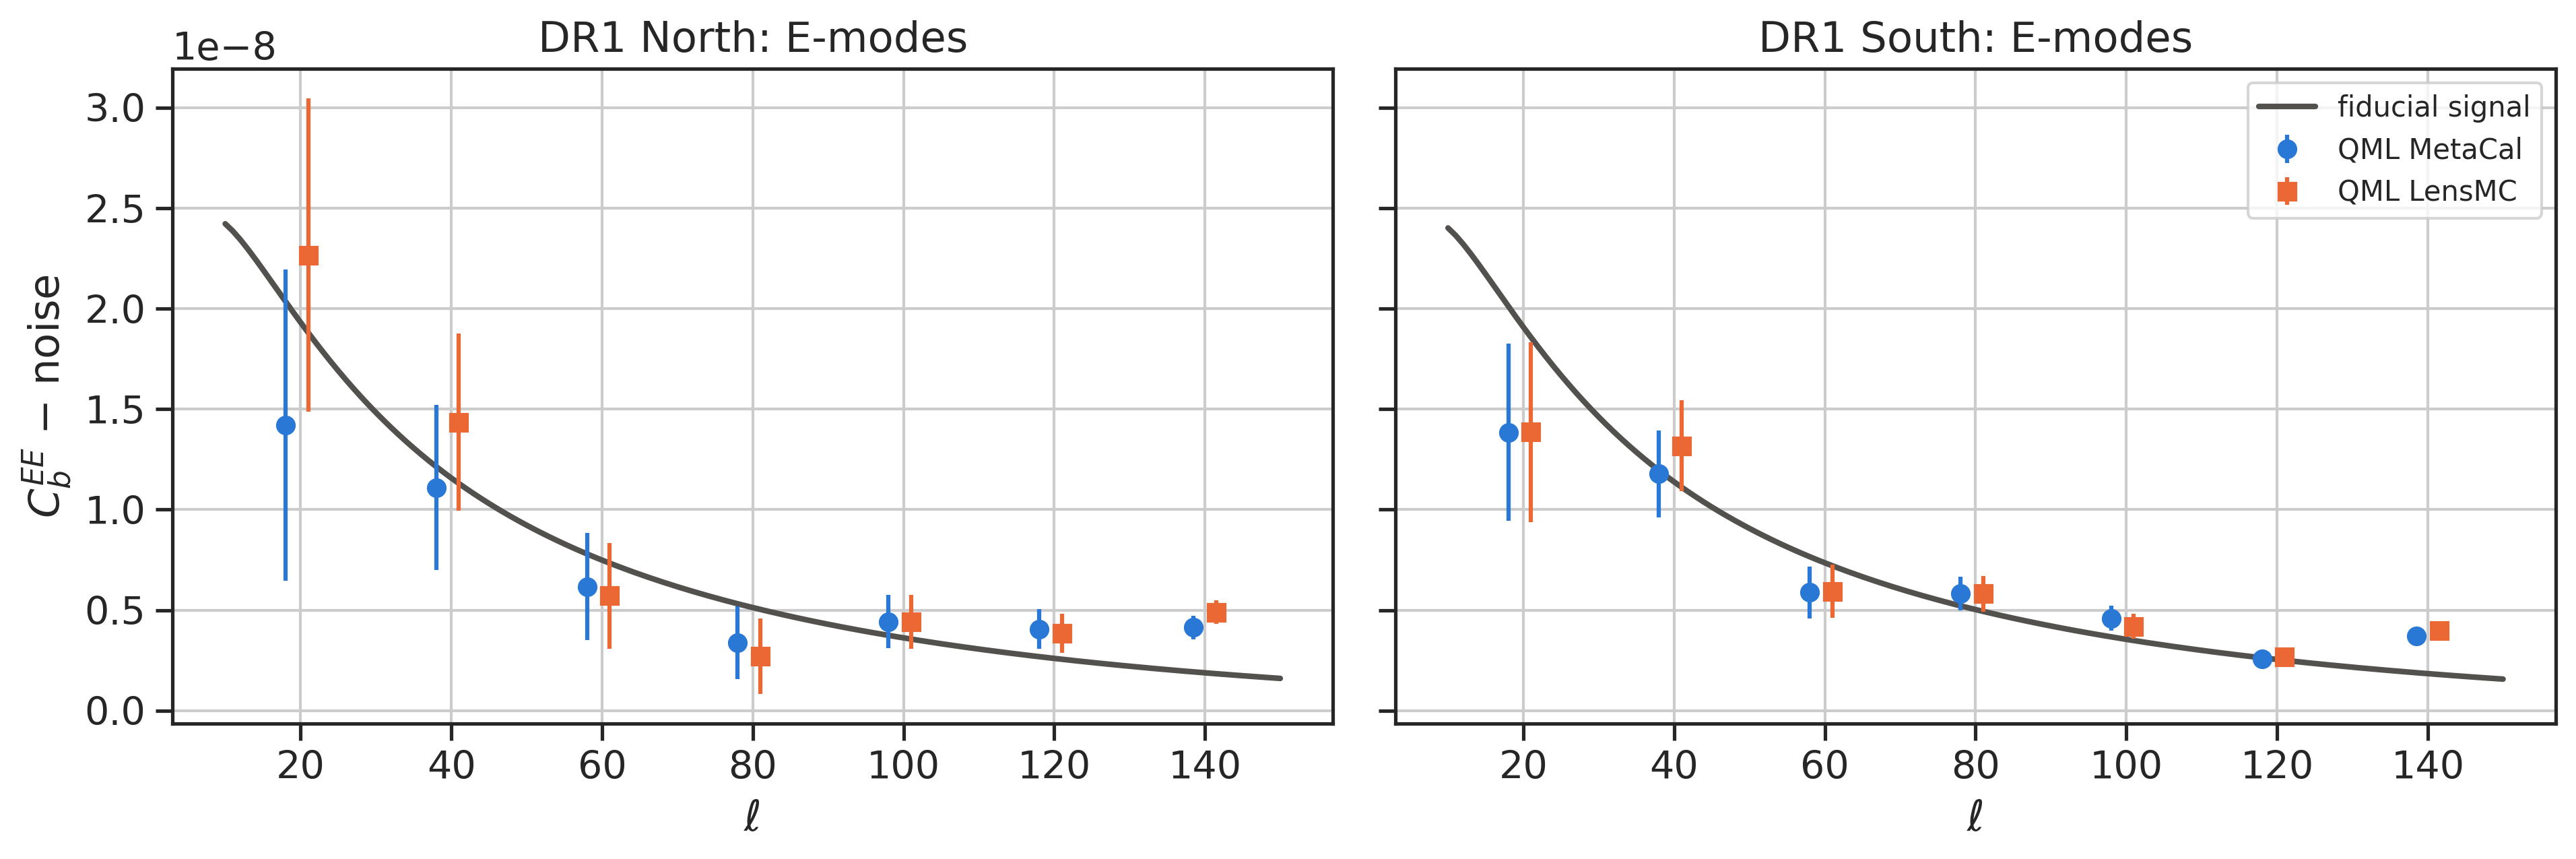

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
ells_plot = np.arange(10, 151)
for ax, (f, flabel) in zip(axes, FIELDS.items()):
    ax.plot(ells_plot, runs['metacal', f]['cl_EE_theory_pw'][ells_plot], color=INK, lw=2, label='fiducial signal')
    for shift, (m, (mlabel, col, mk)) in zip([-1.5, 1.5], METHODS.items()):
        r = runs[m, f]
        ax.errorbar(ell_bp + shift, r['EE_sig'], r['sig_EE'], fmt=mk, color=col, ms=6, capsize=0, label=f'QML {mlabel}')
    ax.set_xlabel('ℓ')
    ax.set_title(f'DR1 {flabel}: E-modes')
axes[0].set_ylabel('$C_b^{EE}$ − noise')
axes[1].legend(fontsize=10)
fig.tight_layout()
fig.savefig(f'{fig_dir}/ee_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

## B-modes

QML $B$-mode bandpowers with the noise removed, which should be zero. Top: in units of $10^{-9}$. Bottom: the same
divided by the QML error, so a point above the grey band ($\pm 3\sigma$) is a significant detection of $B$-modes.
The top band ($\ell$ 130--150) lies above $2N_{\rm side}=128$ and is high in every run.

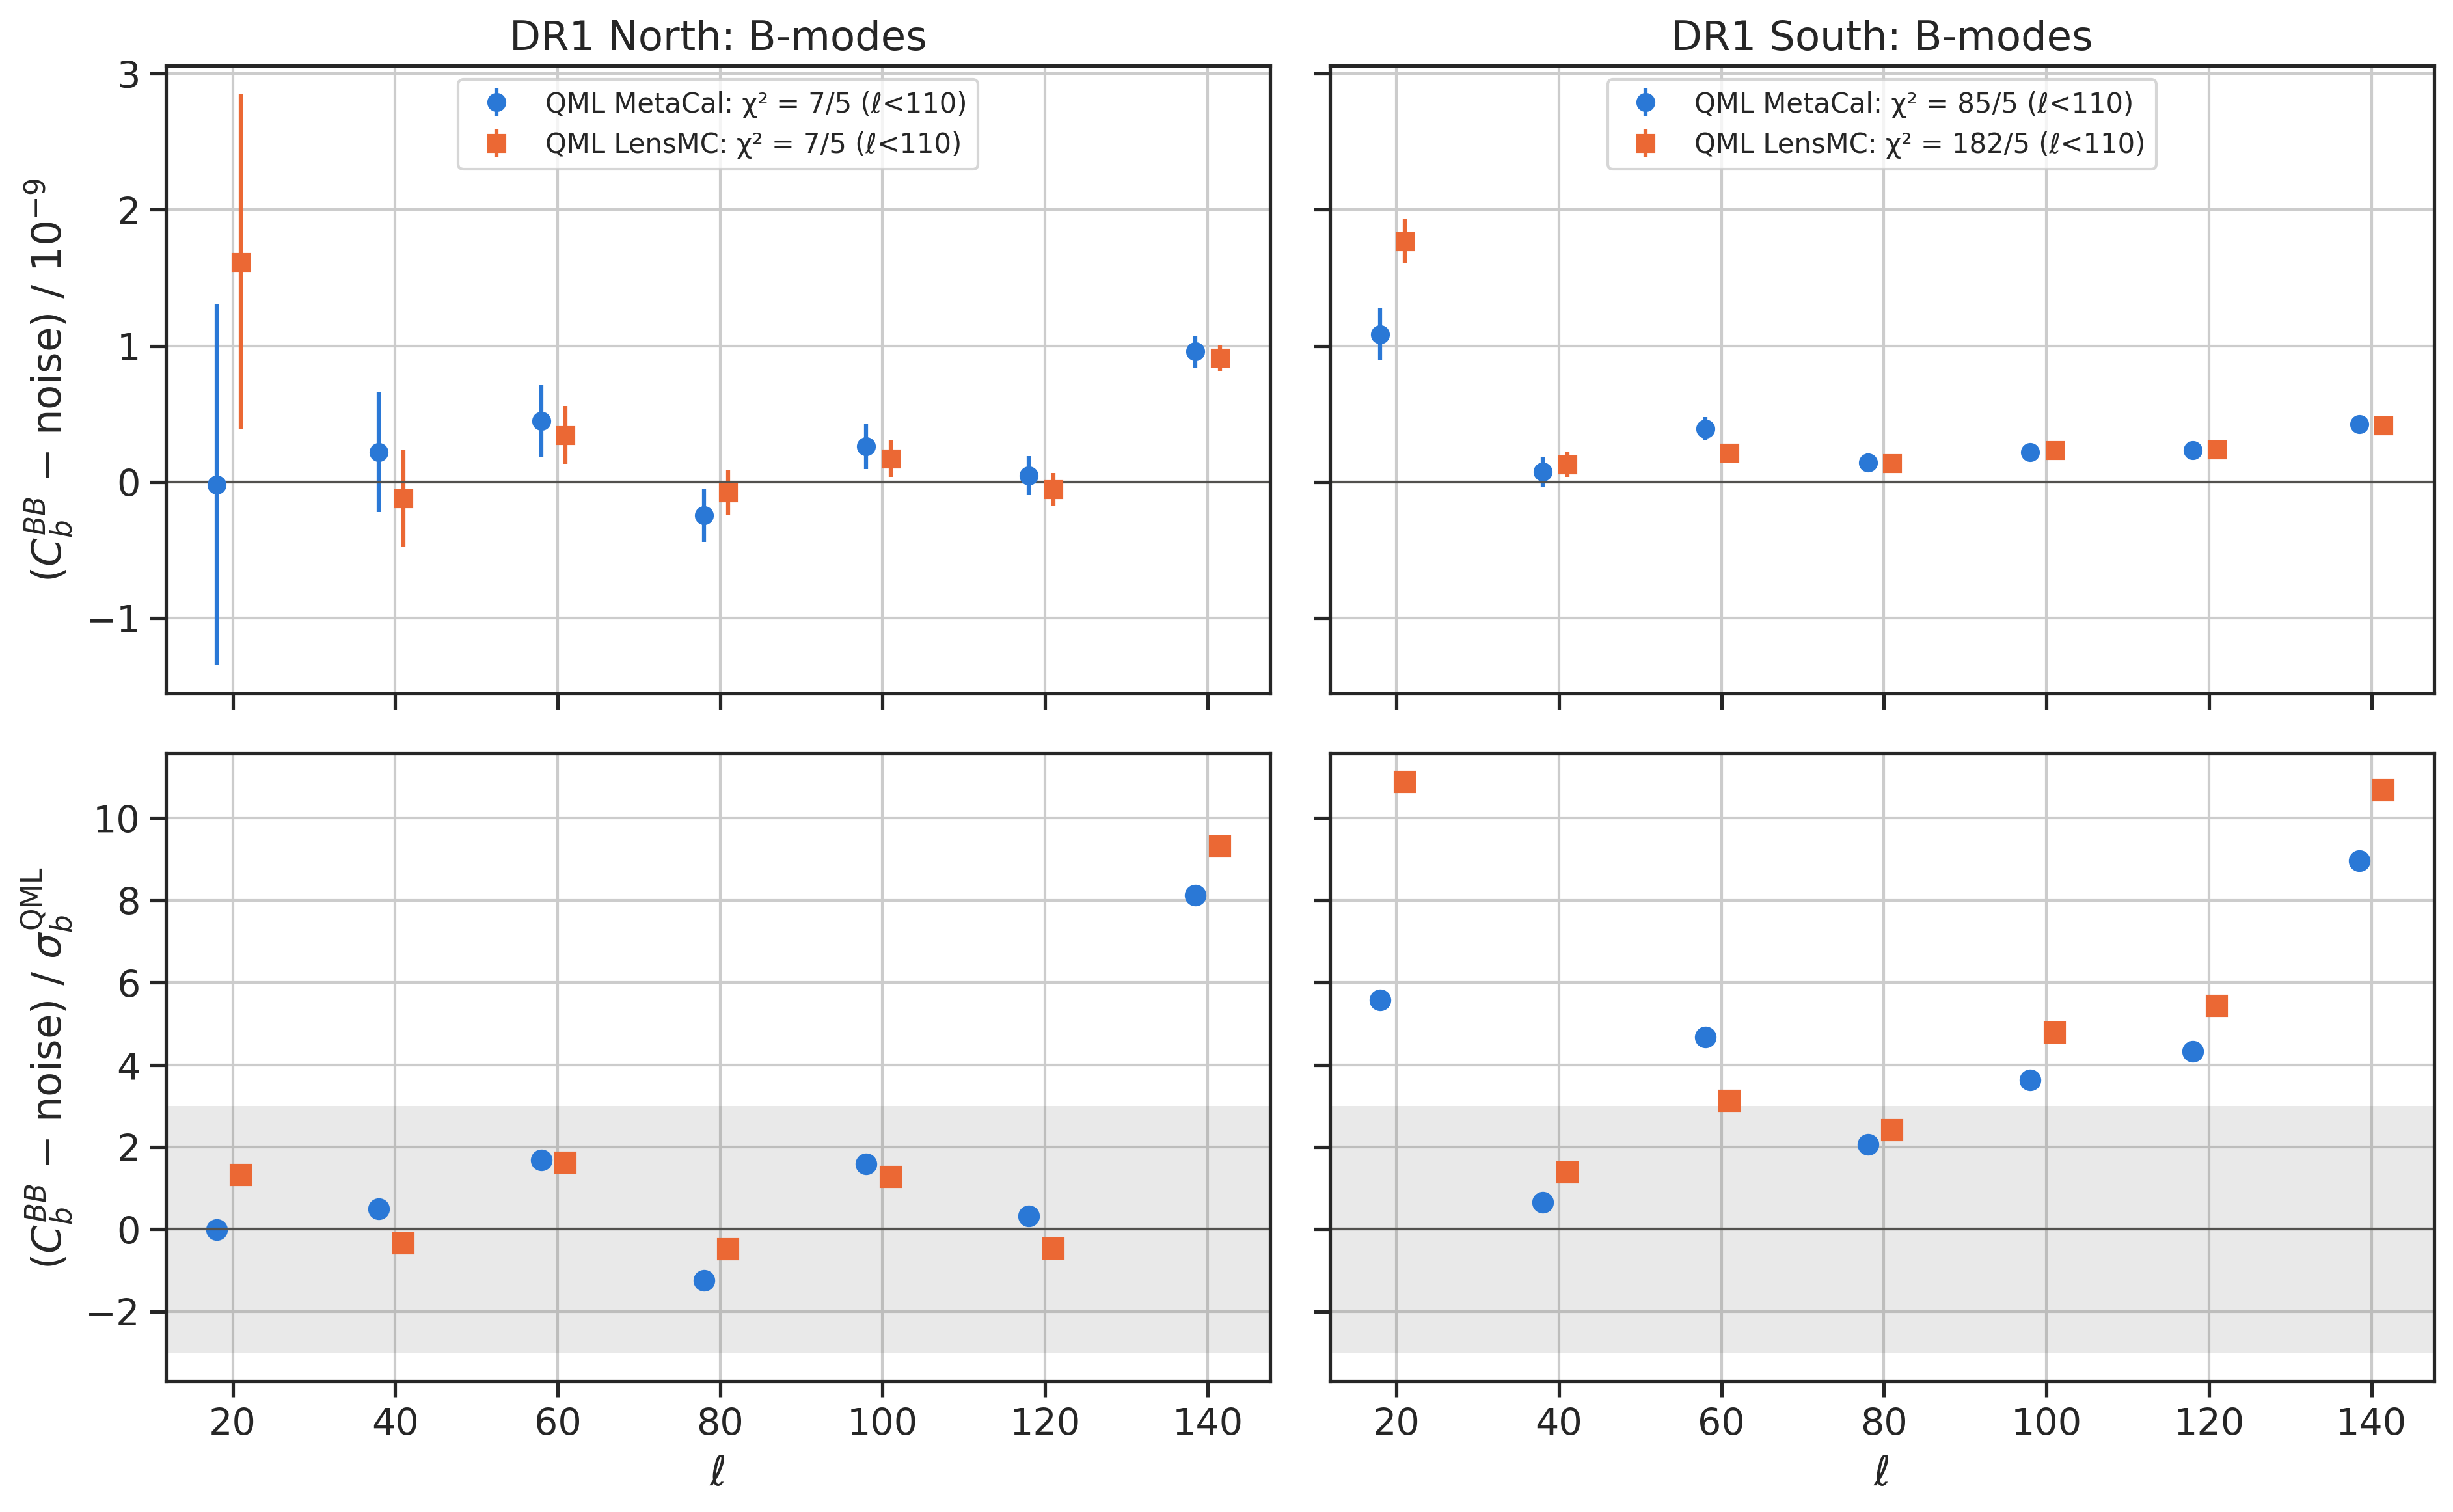

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey='row')
for j, (f, flabel) in enumerate(FIELDS.items()):
    for shift, (m, (mlabel, col, mk)) in zip([-1.5, 1.5], METHODS.items()):
        r = runs[m, f]
        lab = f'QML {mlabel}: χ² = {r["chi2_BB"]:.0f}/5 (ℓ<110)'
        axes[0, j].errorbar(ell_bp + shift, r['BB_sig'] / 1e-9, r['sig_BB'] / 1e-9, fmt=mk, color=col, ms=6,
                            capsize=0, label=lab)
        axes[1, j].plot(ell_bp + shift, r['BB_sig'] / r['sig_BB'], mk, color=col, ms=7)
    axes[0, j].axhline(0, color=INK, lw=1)
    axes[1, j].axhline(0, color=INK, lw=1)
    axes[1, j].axhspan(-3, 3, color=INK, alpha=0.12, lw=0)
    axes[0, j].set_title(f'DR1 {flabel}: B-modes')
    axes[0, j].legend(fontsize=10, loc='upper center')
    axes[1, j].set_xlabel('ℓ')
axes[0, 0].set_ylabel('$(C_b^{BB}$ − noise$)$ / $10^{-9}$')
axes[1, 0].set_ylabel('$(C_b^{BB}$ − noise$)$ / $\\sigma_b^{\\rm QML}$')
fig.tight_layout()
fig.savefig(f'{fig_dir}/bb_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

## B-modes relative to the E signal

$(C_b^{BB} - N)/C_b^{EE,\rm fid}$: the size of the $B$-modes as a fraction of the expected lensing signal.

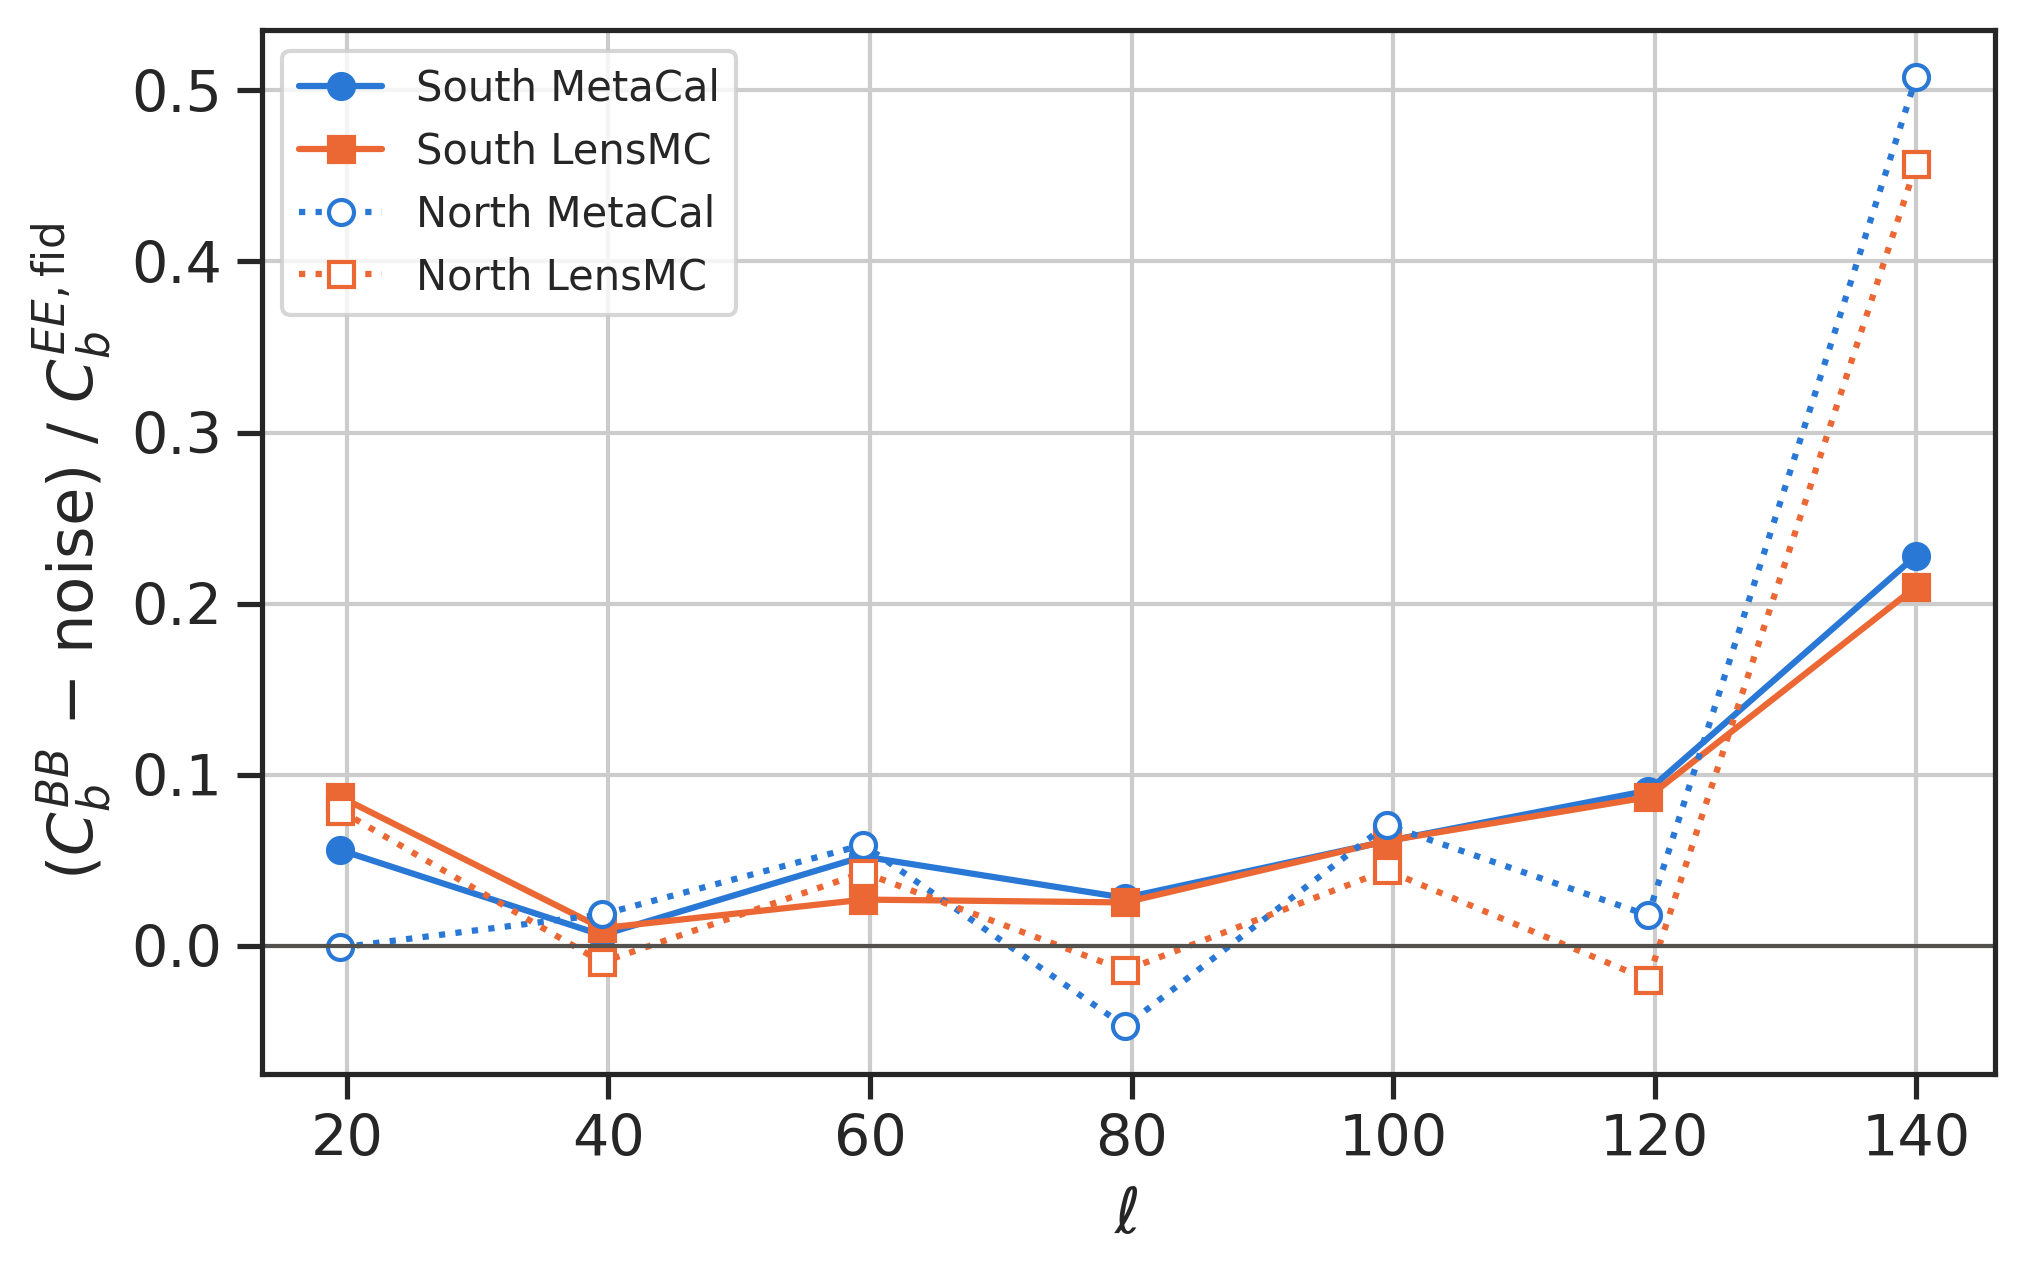

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for f, ls in [('south', '-'), ('north', ':')]:
    for m, (mlabel, col, mk) in METHODS.items():
        r = runs[m, f]
        ax.plot(ell_bp, r['BB_sig'] / r['theory_b'], ls + mk, color=col, mfc=col if f == 'south' else 'white',
                label=f'{FIELDS[f]} {mlabel}')
ax.axhline(0, color=INK, lw=1)
ax.set_xlabel('ℓ')
ax.set_ylabel('$(C_b^{BB}$ − noise$)$ / $C_b^{EE,\\rm fid}$')
ax.legend(fontsize=10)
fig.tight_layout()
fig.savefig(f'{fig_dir}/bb_over_ee.png', dpi=200, bbox_inches='tight')
plt.show()